# Step 1: Process 10 base photos into normalized linear colors

In [1]:
import os
import sys
from pathlib import Path
from PIL import Image, ImageDraw
from typing import Tuple, Dict
import json
import joblib

import numpy as np
import pandas as pd
from scipy.optimize import nnls
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import seaborn as sns
from cmap import Colormap

sys.path.append('../')

mpl.rcParams['figure.dpi'] = 150
mpl.rcParams['font.size'] = 10
mpl.rcParams['font.family'] = 'arial'

sensor_colors = [
    '#8686D2',
    '#7BAED3',
    '#9CCBA0',
    '#E6DC84',
    '#D47291',
    '#868686',
]

In [2]:
def load_image_linear_rgb(path: Path) -> np.ndarray:
    """Load a JPG and convert to linear RGB using the sRGB inverse EOTF."""
    im = Image.open(path).convert('RGB')
    rgb = np.asarray(im, dtype=np.float32) / 255.0  # sRGB (display-referred)
    # sRGB inverse EOTF to get linear-light
    a = 0.055
    low = (rgb <= 0.04045).astype(np.float32)
    high = 1.0 - low
    lin = (rgb / 12.92) * low + (((rgb + a) / (1 + a)) ** 2.4) * high
    return lin

def bw_normalize(img_lin: np.ndarray, white_lin: np.ndarray, black_lin: np.ndarray) -> np.ndarray:
    """Per-channel affine normalization with session white & black references."""
    eps = 1e-8
    return (img_lin - black_lin) / np.maximum(white_lin - black_lin, eps)

def mean_center_roi(img: np.ndarray, frac: float) -> np.ndarray:
    """Mean RGB over a centered square ROI occupying 'frac' of width/height."""
    h, w, _ = img.shape
    dh = int(h * frac / 2)
    dw = int(w * frac / 2)
    cy, cx = h // 2, w // 2
    roi = img[cy - dh:cy + dh, cx - dw:cx + dw, :]
    return roi.reshape(-1, 3).mean(axis=0)

def process_camera_bases(photo_root: Path, roi_frac: float) -> Tuple[Dict[int, np.ndarray], Dict[int, np.ndarray]]:
    """Return dicts: CamSkin[i]->(3,), CamTissue[j]->(3,) in linear, white/black normalized RGB."""
    white_path = photo_root / 'white.jpg'
    black_path = photo_root / 'black.jpg'
    if not white_path.exists() or not black_path.exists():
        raise FileNotFoundError(f"Missing white/black reference images at {white_path} / {black_path}")
    
    white_lin = load_image_linear_rgb(white_path)
    black_lin = load_image_linear_rgb(black_path)
    white_ref = mean_center_roi(white_lin, frac=roi_frac)
    black_ref = mean_center_roi(black_lin, frac=roi_frac)

    cam_skin_dict = {}
    cam_tissue_dict = {}

    # process base skins S1-S5
    for i in range(1, 6):
        p = photo_root / 'base_skin' / f'S{i}.jpg'
        if not p.exists():
            raise FileNotFoundError(f"Missing skin base image at {p}")
        img_lin = load_image_linear_rgb(p)
        img_n = bw_normalize(img_lin, white_ref, black_ref)
        cam_skin_dict[i] = mean_center_roi(img_n, frac=roi_frac)

    # process base tissues T1-T5
    for j in range(1, 6):
        p = photo_root / 'base_tissue' / f'T{j}.jpg'
        if not p.exists():
            raise FileNotFoundError(f"Missing tissue base image at {p}")
        img_lin = load_image_linear_rgb(p)
        img_n = bw_normalize(img_lin, white_ref, black_ref)
        cam_tissue_dict[j] = mean_center_roi(img_n, frac=roi_frac)

    return cam_skin_dict, cam_tissue_dict

In [3]:
photo_root = '../data/ecoflex/ecoflex_sample_photo/'
print('Photo root:', photo_root)

out_dir = Path('../data/ecoflex/camera_processed/')
os.makedirs(out_dir, exist_ok=True)

roi_frac = 0.02  # fraction of image width/height for ROI
skin_out = f'ecoflex_cam_skin_bases_{roi_frac}.npy'
tissue_out = f'ecoflex_cam_tissue_bases_{roi_frac}.npy'

# detect if already processed
if (out_dir / skin_out).exists() and (out_dir / tissue_out).exists():
    print('Processed camera base colors already exist at', out_dir)
else:
    print('Processing camera base colors...')
    cam_skin_bases, cam_tissue_bases = process_camera_bases(Path(photo_root), roi_frac=roi_frac)

    np.save(out_dir / skin_out, np.stack([cam_skin_bases[i] for i in range(1, 6)], axis=0))
    np.save(out_dir / tissue_out, np.stack([cam_tissue_bases[j] for j in range(1, 6)], axis=0))
    with open(out_dir / f'cam_skin_{roi_frac}.json', 'w') as f:
        json.dump({i: cam_skin_bases[i].tolist() for i in cam_skin_bases}, f, indent=2)
    with open(out_dir / f'cam_tissue_{roi_frac}.json', 'w') as f:
        json.dump({j: cam_tissue_bases[j].tolist() for j in cam_tissue_bases}, f, indent=2)
    print('Saved processed camera base colors to', out_dir)

Photo root: ../data/ecoflex/ecoflex_sample_photo/
Processed camera base colors already exist at ..\data\ecoflex\camera_processed


## ROI visualization helper

In [4]:
def preview_center_roi(img_path: str, frac: float, save_path: str = None):
    p = Path(img_path)
    if not p.exists():
        raise FileNotFoundError(f'Image not found: {img_path}')
    im = Image.open(p).convert('RGB')
    w, h = im.size
    dw = int(w * frac / 2.0)
    dh = int(h * frac / 2.0)
    cx, cy = w // 2, h // 2
    x0, y0 = cx - dw, cy - dh
    x1, y1 = cx + dw, cy + dh

    # draw rectangle overlay (thick red border for visibility)
    overlay = im.copy()
    draw = ImageDraw.Draw(overlay)
    for off in (-1, 0, 1):
        draw.rectangle([x0-off, y0-off, x1+off, y1+off], outline=(255, 0, 0))

    # print the size of the ROI and mean RGB values
    roi_width = x1 - x0
    roi_height = y1 - y0
    print(f'ROI size: {roi_width} x {roi_height} pixels')
    roi = np.array(im)[y0:y1, x0:x1, :]
    mean_rgb = roi.reshape(-1, 3).mean(axis=0)
    print(f'Mean RGB in ROI: R={mean_rgb[0]:.2f}, G={mean_rgb[1]:.2f}, B={mean_rgb[2]:.2f}')

    # show
    plt.figure(figsize=(6, 6))
    plt.imshow(overlay)
    plt.axis("off")
    plt.title(f"ROI preview (frac={frac:.2f})")
    if save_path is not None:
        plt.savefig(save_path, bbox_inches='tight')
        print(f'Saved ROI preview to {save_path}')
    plt.show()

ROI size: 34 x 22 pixels
Mean RGB in ROI: R=45.54, G=40.64, B=45.02


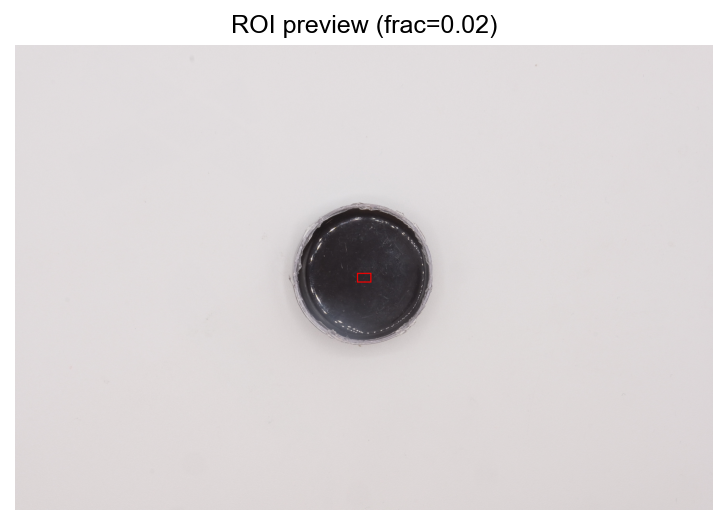

In [5]:
preview_center_roi(photo_root + 'base_tissue/T3.jpg', frac=0.02)

# Step 2: SpectraDerma measurement preprocessing

In [6]:
spectraderma_meas_path = Path('../data/ecoflex/spectraderma_meas.csv')
assert spectraderma_meas_path.exists(), f'SpectraDerma measurement file not found at {spectraderma_meas_path}'

df = pd.read_csv(spectraderma_meas_path)
print('SpectraDerma measurements loaded:', df.shape)
print('Columns:', df.columns.tolist())

SpectraDerma measurements loaded: (125, 11)
Columns: ['tissue_r', 'tissue_b', 'skin_f', 'skin_b', 'rep', 'ch0', 'ch1', 'ch2', 'ch3', 'ch4', 'ch5']


In [7]:
df['skin_i'] = df['skin_f'].astype(int)
df['tissue_j'] = df['tissue_r'].astype(int)

channel_order = ['vio', 'blu', 'grn', 'ylw', 'red', 'nir']
chan_cols = {name: f'ch{k}' for k, name in enumerate(channel_order)}
print('Using channel columns:', chan_cols)

# TODO: This can use the SpectraDerma reading on the white and dark references
session_dark = np.zeros(6, dtype=float)
session_white = np.ones(6, dtype=float)
eq_vector = np.array([0.177, 0.567, 0.982, 0.969, 0.365, 0.050], dtype=float)  # typical 4500K LED SPD

Using channel columns: {'vio': 'ch0', 'blu': 'ch1', 'grn': 'ch2', 'ylw': 'ch3', 'red': 'ch4', 'nir': 'ch5'}


## Preprocess data

In [8]:
def row_to_features(r):
    I = np.array([r[chan_cols[k]] for k in channel_order], dtype=float)
    R = (I - session_dark) / (session_white - session_dark + 1e-12)
    Rtil = R / np.maximum(eq_vector, 1e-12)

    anchor = Rtil[4] if Rtil[4] > 1e-8 else 1.0  # use red as anchor
    Z = Rtil / np.maximum(anchor, 1e-12)
    L = np.log(np.maximum(Rtil, 1e-12))
    feat = np.concatenate([Rtil, Z[[0, 1, 2, 3, 5]], L])

    return Rtil, Z, L, feat

In [9]:
R_list, Z_list, L_list, F_list = [], [], [], []
for _, r in df.iterrows():
    R, Z, L, F = row_to_features(r)
    R_list.append(R)
    Z_list.append(Z)
    L_list.append(L)
    F_list.append(F)

R_arr, Z_arr, L_arr, F_arr = map(np.array, [R_list, Z_list, L_list, F_list])
print('Feature arrays shapes:', F_arr.shape)

Feature arrays shapes: (125, 17)


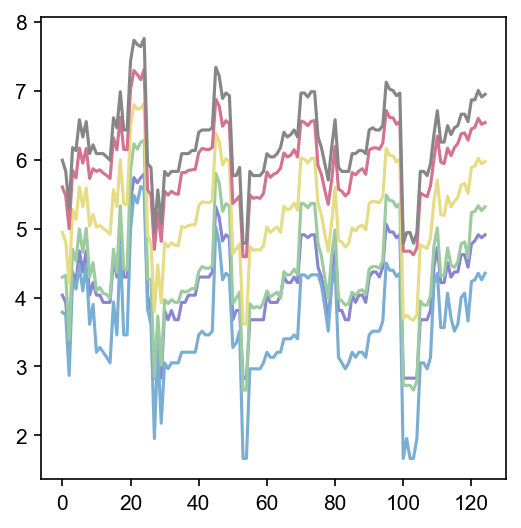

In [10]:
plt.figure(figsize=(4, 4))
for i, l in enumerate(L_arr.T):
    plt.plot(l, label=f'Channel {i}', color=sensor_colors[i])

## Aggregate repetitions by mean

In [11]:
def agg_group(df_idx, arr):
    """Aggregate repetitions per (i, j) pair by mean."""
    out = {}
    var = {}
    for (i, j), sub in df_idx.groupby(['skin_i', 'tissue_j']):
        rows = sub.index.to_numpy()
        out[(i, j)] = np.mean(arr[rows], axis=0)
        var[(i, j)] = np.var(arr[rows], axis=0)
    return out, var

In [12]:
idx_df = df[['skin_i', 'tissue_j', 'rep']].reset_index(drop=True)
R_agg, R_var = agg_group(idx_df, R_arr)
L_agg, L_var = agg_group(idx_df, L_arr)
F_agg, F_var = agg_group(idx_df, F_arr)

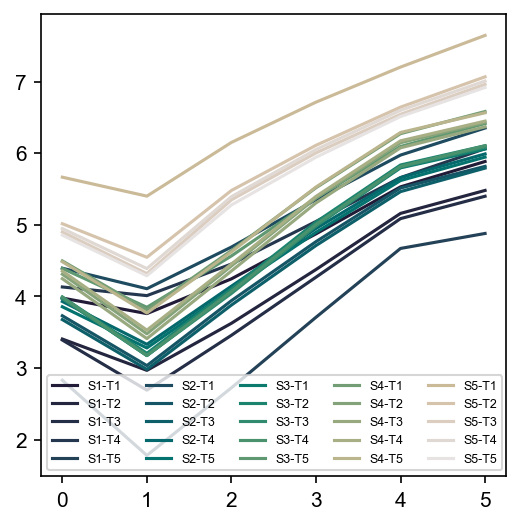

In [13]:
colors = Colormap('cmocean:rain')(np.linspace(0, 1, 26))

plt.figure(figsize=(4, 4))
for i in range(1, 6):
    for j in range(1, 6):
        plt.plot(L_agg[(i, j)], label=f'S{i}-T{j}', color=colors[(i - 1) * 5 + (j - 1)])

plt.legend(ncol=5, fontsize=6)

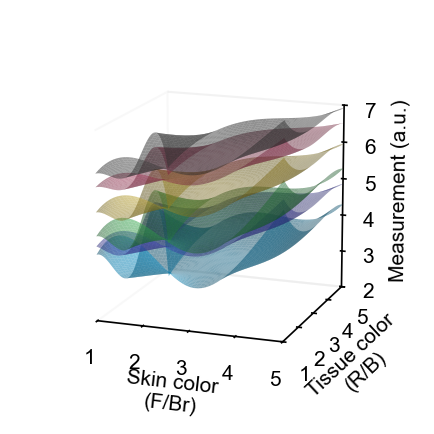

In [15]:
from scipy.interpolate import RegularGridInterpolator

sensor_colors_vivid = [
    '#5C5CFF',  # vivid lavender-blue
    '#00A3E6',  # brighter sky blue
    '#3CCB5A',  # stronger green
    '#F7D53A',  # brighter yellow
    '#E44575',  # vivid pink-red
    '#555555',  # deeper neutral gray
]

num_skin, num_tissue, num_channels = 5, 5, 6
L_cube = np.zeros((num_skin, num_tissue, num_channels))

for (i, j), val in L_agg.items():
    L_cube[i - 1, j - 1, :] = val  # assuming i, j start from 1

dense = 50
skin_new = np.linspace(1, num_skin, dense)
tissue_new = np.linspace(1, num_tissue, dense)
X_new, Y_new = np.meshgrid(skin_new, tissue_new, indexing='ij')

L_smooth = np.zeros((dense, dense, num_channels))
for k in range(num_channels):
    f = RegularGridInterpolator(
        (np.arange(1, num_skin + 1), np.arange(1, num_tissue + 1)),
        L_cube[:, :, k],
        method='cubic',
        bounds_error=False,
        fill_value=None
    )
    pts = np.stack([X_new.ravel(), Y_new.ravel()], axis=-1)
    L_smooth[:, :, k] = f(pts).reshape(dense, dense)

fig = plt.figure(figsize=(3.5, 3.5))
ax = fig.add_subplot(111, projection='3d')

for k in range(num_channels):
    Z = L_smooth[:, :, k]
    # To make surfaces offset slightly in Z for clarity, add small offset
    ax.plot_surface(X_new, Y_new, Z, color=sensor_colors_vivid[k],
                    alpha=0.5, rstride=1, cstride=1, linewidth=0, antialiased=True)

ax.set_xlim(1, num_skin)
ax.set_ylim(1, num_tissue)
ax.set_zlim(2, 7)

ax.view_init(elev=15, azim=-70)
ax.set_box_aspect([1, 1, 1], zoom=0.8)
ax.set_xlabel('Skin color\n(F/Br)')
ax.set_ylabel('Tissue color\n(R/B)')
ax.set_zlabel('Measurement (a.u.)')

ax.grid(False)
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False
# ax.xaxis.line.set_color((1, 1, 1, 0))
# ax.yaxis.line.set_color((1, 1, 1, 0))
# ax.zaxis.line.set_color((1, 1, 1, 0))

pos_ax_3d = ax.get_position()
# plt.savefig('../figures/fig2/ecoflex_Lagg_3d_surface.png', bbox_inches='tight', dpi=600, transparent=True)
plt.show()

## estimate base device vectors (from j=1 and i=1)

In [16]:
dev_base_skin = {i: np.min(F_arr[df.index[(df["skin_i"]==i) & (df["tissue_j"]==1)]], axis=0) for i in range(1, 6)}
dev_base_tissue = {j: np.min(F_arr[df.index[(df["tissue_j"]==j) & (df["skin_i"]==1)]], axis=0) for j in range(1, 6)}
# TODO: this can use the reading from the skin-only and tissue-only phantom measurements

In [17]:
out_dir = Path('../data/ecoflex/device_processed/')
os.makedirs(out_dir, exist_ok=True)

np.save(out_dir / 'stack_F.npy', np.stack([F_agg[(i, j)] for i in range(1, 6) for j in range(1, 6)], axis=0))
np.save(out_dir / 'stack_L.npy', np.stack([L_agg[(i, j)] for i in range(1, 6) for j in range(1, 6)], axis=0))
np.save(out_dir / 'stack_R.npy', np.stack([R_agg[(i, j)] for i in range(1, 6) for j in range(1, 6)], axis=0))
np.save(out_dir / 'dev_base_skin.npy', np.stack([dev_base_skin[i] for i in range(1, 6)], axis=0))
np.save(out_dir / 'dev_base_tissue.npy', np.stack([dev_base_tissue[j] for j in range(1, 6)], axis=0))

manifest = {
    'channel_order': channel_order,
    'chan_cols': chan_cols,
    'session_dark': session_dark.tolist(),
    'session_white': session_white.tolist(),
    'eq_vector': eq_vector.tolist(),
    'notes': 'Features F = [Rtil(6), Z(no-red)(5), log(Rtil)(6)]',
}
with open(out_dir / 'manifest.json', 'w') as f:
    json.dump(manifest, f, indent=2)

print('Saved processed SpectraDerma data to', out_dir)
print('Example aggregated stack feature shape:', np.load(out_dir / 'stack_F.npy').shape)

Saved processed SpectraDerma data to ..\data\ecoflex\device_processed
Example aggregated stack feature shape: (25, 17)


# Step 3: Layer-aware composition for the 25 stacks

## estimate α, β from device logs

In [18]:
dev_dir = Path('../data/ecoflex/device_processed/')
cam_dir = Path('../data/ecoflex/camera_processed/')

stack_L         = np.load(dev_dir / "stack_L.npy")             # (25, 6) log-features per stack
base_skin_F     = np.load(dev_dir / "dev_base_skin.npy")       # (5, 17) device base features
base_tissue_F   = np.load(dev_dir / "dev_base_tissue.npy")     # (5, 17)
cam_skin        = np.load(cam_dir / "ecoflex_cam_skin_bases_0.02.npy")             # (5, 3) camera-linear base colors
cam_tissue      = np.load(cam_dir / "ecoflex_cam_tissue_bases_0.02.npy")           # (5, 3)

In [19]:
# Extract log-features L (last 6 elements of our Step 2 feature vector)
base_skin_L = base_skin_F[:, -6:]  # (5, 6)
base_tissue_L = base_tissue_F[:, -6:]  # (5, 6)

# Channel weights based on LED temperature (4500K)
w = np.array([0.177, 0.567, 0.982, 0.969, 0.365, 0.050], dtype=float)

In [20]:
def solve_ab(L_stack, L_skin, L_tissue, w):
    """
    Minimize sum_k w_k * (L_stack_k - alpha*L_skin_k - beta*L_tissue_k)^2, with alpha,beta >= 0.
    """
    A = np.column_stack([L_skin, L_tissue]) * w[:, None]    # (6, 2)
    y = L_stack * w                                         # (6,)
    ab, _ = nnls(A, y)
    return ab[0], ab[1]

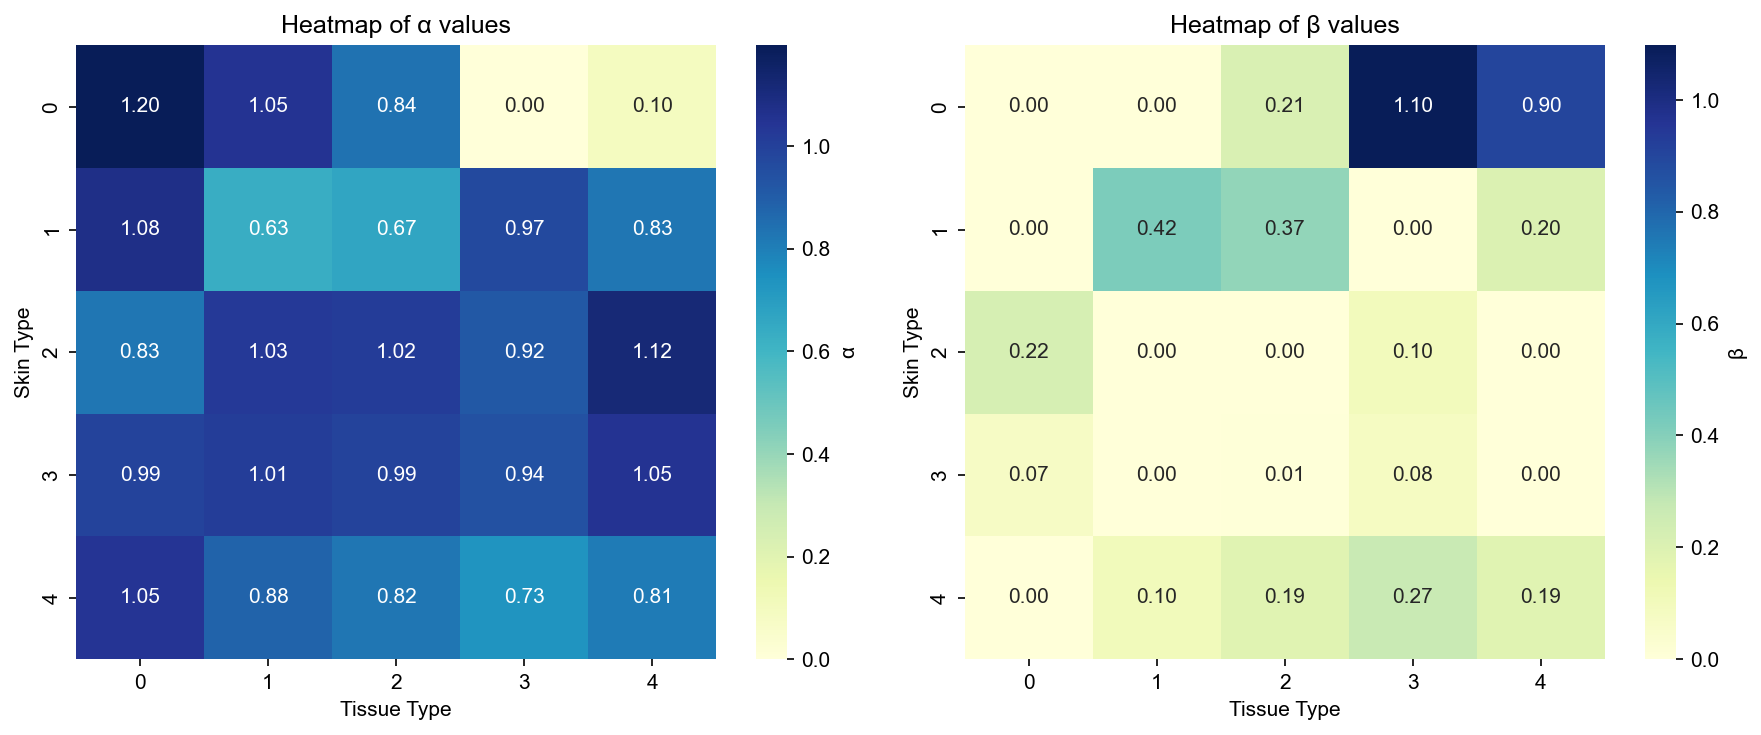

Saved alphabeta.npy to ..\data\ecoflex\device_processed\alphabeta.npy


In [21]:
alphabeta = np.zeros((5, 5, 2), dtype=float)  # [i-1, j-1] -> (alpha, beta)
for i in range(5):
    for j in range(5):
        idx = i * 5 + j  # stack index
        a, b = solve_ab(stack_L[idx], base_skin_L[i], base_tissue_L[j], w)
        alphabeta[i, j] = (a, b)

# make two heatmaps for α, β
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.heatmap(alphabeta[:, :, 0], annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label': 'α'})
plt.title('Heatmap of α values')
plt.xlabel('Tissue Type')
plt.ylabel('Skin Type')

plt.subplot(1, 2, 2)
sns.heatmap(alphabeta[:, :, 1], annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label': 'β'})
plt.title('Heatmap of β values')
plt.xlabel('Tissue Type')
plt.ylabel('Skin Type')

plt.tight_layout()
plt.show()

# np.save(dev_dir / 'alphabeta.npy', alphabeta)
print('Saved alphabeta.npy to', dev_dir / 'alphabeta.npy')

## Compose camera-space colors for all 25 stacks + save grid preview

In [23]:
alphabeta = np.load(dev_dir / 'alphabeta.npy')  # (5, 5, 2)

stack_color_cam = np.zeros((5, 5, 3), dtype=float)  # [i-1, j-1] -> (R, G, B)
for i in range(5):
    for j in range(5):
        a, b = alphabeta[i, j]
        stack_color_cam[i, j] = a * cam_skin[i] + b * cam_tissue[j]

# np.save(cam_dir / 'ecoflex_stack_colors_cam.npy', stack_color_cam)
print('Saved ecoflex_stack_colors_cam.npy to', cam_dir / 'ecoflex_stack_colors_cam.npy')

Saved ecoflex_stack_colors_cam.npy to ..\data\ecoflex\camera_processed\ecoflex_stack_colors_cam.npy


In [24]:
def lin_to_srgb(lin):
    lin = np.clip(lin, 0, 1)
    a = 0.055
    low = lin <= 0.0031308
    srgb = np.empty_like(lin)
    srgb[low]  = 12.92 * lin[low]
    srgb[~low] = (1 + a) * (lin[~low] ** (1/2.4)) - a
    return np.clip(srgb, 0, 1)

Saved 5×5 color grid preview to: ..\data\ecoflex\camera_processed\stack_color_grid.png


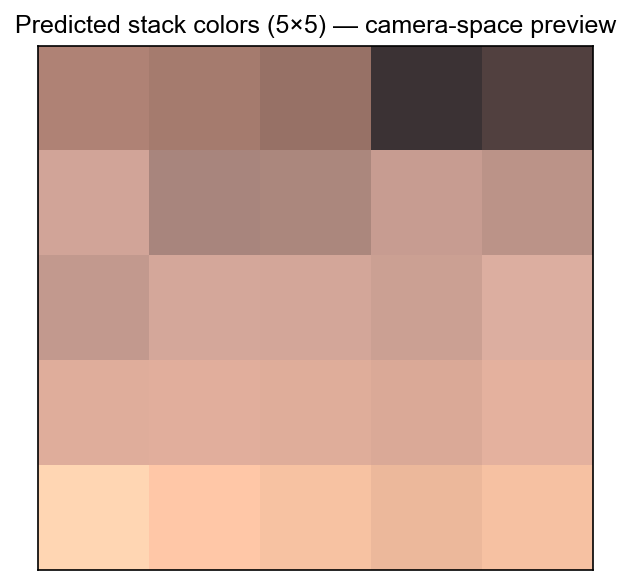

In [25]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.set_xlim(0,5); ax.set_ylim(0,5); ax.set_xticks([]); ax.set_yticks([])
for i in range(5):
    for j in range(5):
        rgb = lin_to_srgb(stack_color_cam[i, j])
        rect = plt.Rectangle((j, 4-i), 1, 1, edgecolor='black', linewidth=0)
        rect.set_facecolor(rgb)
        ax.add_patch(rect)
ax.set_title("Predicted stack colors (5×5) — camera-space preview")
plt.tight_layout()

grid_path = cam_dir / "stack_color_grid.png"
# fig.savefig(grid_path, dpi=600)
print("Saved 5×5 color grid preview to:", grid_path)

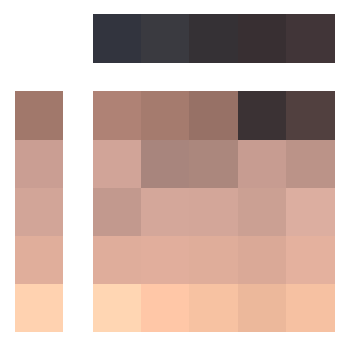

In [26]:
fig = plt.figure(figsize=(2.75, 2.75))
gs  = GridSpec(nrows=2, ncols=2, height_ratios=[0.2, 1.0], width_ratios=[0.2, 1.0], figure=fig)

skin_cam_srgb = lin_to_srgb(cam_skin)  # (5, 3)
tissue_cam_srgb = lin_to_srgb(cam_tissue)  # (5, 3)

ax_top  = fig.add_subplot(gs[0, 1])   # tissue strip (x-axis)
ax_left = fig.add_subplot(gs[1, 0])   # skin strip (y-axis)
ax_main = fig.add_subplot(gs[1, 1])   # 5×5 grid

for i in range(5):
    for j in range(5):
        rgb = lin_to_srgb(stack_color_cam[i, j])
        rect = plt.Rectangle((j, 4-i), 1, 1, edgecolor='white', linewidth=0.)
        rect.set_facecolor(rgb)
        ax_main.add_patch(rect)

ax_main.set_xlim(0, 5)
ax_main.set_ylim(0, 5)
ax_main.set_xticks([])
ax_main.set_yticks([])
for spine in ax_main.spines.values():
    spine.set_visible(False)

for j in range(5):
    rect = plt.Rectangle((j, 0), 1, 1, edgecolor='none', facecolor=tissue_cam_srgb[j])
    ax_top.add_patch(rect)
ax_top.set_xlim(0, 5)
ax_top.set_ylim(0, 1)
ax_top.set_xticks([])
ax_top.set_yticks([])
ax_top.set_aspect('auto')
ax_top.set_frame_on(False)


for i in range(5):
    rect = plt.Rectangle((0, 4 - i), 1, 1, edgecolor='none', facecolor=skin_cam_srgb[i])
    ax_left.add_patch(rect)
ax_left.set_xlim(0, 1)
ax_left.set_ylim(0, 5)
ax_left.set_xticks([])
ax_left.set_yticks([])
ax_left.set_aspect('auto')
ax_left.set_frame_on(False)

# ax_top.text(0, 1.02, "Tissue →", va='bottom', ha='left', fontsize=9)
# ax_left.text(-0.02, 5, "Skin ↓", va='top', ha='right', rotation=90, fontsize=9)

# fig.savefig('../figures/fig2/stack_color_grid.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

# Step 4: Regressor

In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error

In [28]:
X_path = dev_dir / 'stack_F.npy'
X = np.load(X_path)  # (25, 17)

Y_path = cam_dir / 'ecoflex_stack_colors_cam.npy'
Y = np.load(Y_path)  # (5, 5, 3)
Y = Y.reshape(-1, 3)  # (25, 3)

model_dir = Path('../data/ecoflex/processed_models/')
os.makedirs(model_dir, exist_ok=True)

In [29]:
def camrgb_to_lab(camrgb):
    eps = 216/24389; kappa = 24389/27
    Xc, Yc, Zc = camrgb[...,0], camrgb[...,1], camrgb[...,2]
    def f(t): return np.where(t>eps, np.cbrt(t), (kappa*t + 16)/116)
    fx, fy, fz = f(Xc), f(Yc), f(Zc)
    L = 116*fy - 16; a = 500*(fx - fy); b = 200*(fy - fz)
    return np.stack([L,a,b], axis=-1)

def delta_e_lab(c1, c2):
    l1, l2 = camrgb_to_lab(c1), camrgb_to_lab(c2)
    return np.linalg.norm(l1 - l2, axis=-1)

loo = LeaveOneOut()

def cv_eval(model_builder):
    preds, trues = [], []
    for tr, te in loo.split(X):
        sc = StandardScaler().fit(X[tr])
        Xtr, Xte = sc.transform(X[tr]), sc.transform(X[te])
        ytr, yte = Y[tr], Y[te]

        model = model_builder().fit(Xtr, ytr)
        ypred = model.predict(Xte)
        preds.append(ypred[0])
        trues.append(yte[0])

    preds = np.stack(preds)
    trues = np.stack(trues)
    rmse = float(np.sqrt(mean_squared_error(trues, preds)))
    delta_e = delta_e_lab(preds, trues)

    return {
        'rmse': rmse,
        # 'delta_e_mean': float(np.mean(delta_e)),
        'delta_e_median': float(np.median(delta_e)),
        'delta_e_95': float(np.percentile(delta_e, 95)),
    }

In [30]:
# grids
ridge_alphas = [0.0, 0.01, 0.1, 0.3, 1.0, 3.0, 10.0]
pls_comps = [2, 3, 4]

ridge_scores = [{**cv_eval(lambda a=a: Ridge(alpha=a)), 'alpha': a} for a in ridge_alphas]
pls_scores = [{**cv_eval(lambda n=n: PLSRegression(n_components=n)), 'n_components': n} for n in pls_comps]

best_ridge = min(ridge_scores, key=lambda x: x['delta_e_median'])
best_pls = min(pls_scores, key=lambda x: x['delta_e_median'])
use_pls = best_pls['delta_e_median'] < best_ridge['delta_e_median']

print('Ridge CV results:', ridge_scores)
print('PLS CV results:', pls_scores)
print('Selected model:', 'PLS' if use_pls else 'Ridge', (best_pls if use_pls else best_ridge))

Ridge CV results: [{'rmse': 0.16984276146926483, 'delta_e_median': 6.146159460101066, 'delta_e_95': 80.92818683070729, 'alpha': 0.0}, {'rmse': 0.10908483244482792, 'delta_e_median': 6.380471720217933, 'delta_e_95': 54.29072422905736, 'alpha': 0.01}, {'rmse': 0.10024501835930522, 'delta_e_median': 4.860496928150444, 'delta_e_95': 39.64484571949256, 'alpha': 0.1}, {'rmse': 0.09468969212289512, 'delta_e_median': 4.125486424575716, 'delta_e_95': 34.749526102745904, 'alpha': 0.3}, {'rmse': 0.08966065104616203, 'delta_e_median': 3.9803881271237165, 'delta_e_95': 30.639787531988986, 'alpha': 1.0}, {'rmse': 0.08675042785660186, 'delta_e_median': 4.248547278924831, 'delta_e_95': 28.035104371210274, 'alpha': 3.0}, {'rmse': 0.08634660698326659, 'delta_e_median': 4.674380544504194, 'delta_e_95': 26.669257243628717, 'alpha': 10.0}]
PLS CV results: [{'rmse': 0.08550455611706137, 'delta_e_median': 5.115336952114723, 'delta_e_95': 25.912552738922724, 'n_components': 2}, {'rmse': 0.08636850751633678, '

In [31]:
# train on all 25
scaler = StandardScaler().fit(X)
Xs = scaler.transform(X)

if use_pls:
    model = PLSRegression(n_components=best_pls['n_components']).fit(Xs, Y)
    meta = {'type': 'PLS', 'n_components': best_pls['n_components']}
else:
    model = Ridge(alpha=best_ridge['alpha']).fit(Xs, Y)
    meta = {'type': 'Ridge', 'alpha': best_ridge['alpha']}

In [32]:
# joblib.dump(model, model_dir / 'ecoflex_cam_model.pkl')
# joblib.dump(scaler, model_dir / 'ecoflex_cam_scaler.pkl')
# with open(model_dir / 'ecoflex_cam_model_meta.json', 'w') as f:
#     json.dump({
#         'Y_source': str(Y_path),
#         'X_source': str(X_path),
#         'model_meta': meta,
#         'feature_layout': 'F = [Rtil(6), Z(no-red)(5), log(Rtil)(6)]',
#         'channel_order': channel_order,
#     }, f, indent=2)
# print('Saved trained camera model to', model_dir)

# Step 5: Visualize regression

In [33]:
ins_preds = None

model = joblib.load(model_dir / 'ecoflex_cam_model.pkl')
scaler = joblib.load(model_dir / 'ecoflex_cam_scaler.pkl')
Xs = scaler.transform(X)
ins_preds = model.predict(Xs)

with open(model_dir / 'ecoflex_cam_model_meta.json', 'r') as f:
    meta = json.load(f)
print('Loaded trained model meta:', meta.get('model_meta', {}))

Loaded trained model meta: {'type': 'PLS', 'n_components': 4}


In [34]:
def cv_eval_with_preds(model_builder, X, Y):
    """
    Returns LOOCV predictions, truths, ΔE (Lab), and RMSE for a given model builder.
    Does not modify or depend on cv_eval(); it mirrors the loop internally.
    """
    loo = LeaveOneOut()
    preds, trues = [], []
    for tr, te in loo.split(X):
        sc  = StandardScaler().fit(X[tr])
        Xtr = sc.transform(X[tr])
        Xte = sc.transform(X[te])
        ytr, yte = Y[tr], Y[te]

        model = model_builder().fit(Xtr, ytr)
        ypred = model.predict(Xte)
        preds.append(ypred[0])
        trues.append(yte[0])

    preds = np.stack(preds)
    trues = np.stack(trues)
    dE = delta_e_lab(preds, trues)
    rmse = float(np.sqrt(mean_squared_error(trues, preds)))
    return {"preds": preds, "trues": trues, "delta_e": dE, "rmse": rmse}

In [35]:
if use_pls:
    res = cv_eval_with_preds(lambda n=best_pls['n_components']: PLSRegression(n_components=n), X, Y)
    best_label = f"PLS (n_components={best_pls['n_components']})"
else:
    res = cv_eval_with_preds(lambda a=best_ridge['alpha']: Ridge(alpha=a), X, Y)
    best_label = f"Ridge (alpha={best_ridge['alpha']})"

cv_preds, cv_trues, cv_de = res['preds'], res['trues'], res['delta_e']
print(f"{best_label} — LOOCV RMSE: {res['rmse']:.6f}, ΔE median: {float(np.median(cv_de)):.4f}, 95th: {float(np.percentile(cv_de,95)):.4f}")

PLS (n_components=4) — LOOCV RMSE: 0.088731, ΔE median: 3.9312, 95th: 28.1053


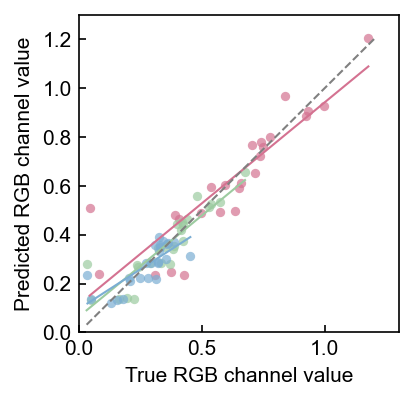

In [36]:
# === Overlayed parity plot with linear fits for R, G, B ===
import numpy as np
import matplotlib.pyplot as plt

labels = ["R", "G", "B"]
colors = [sensor_colors[4], sensor_colors[2], sensor_colors[1]]  # red, green, blue

plt.figure(figsize=(2.75, 2.75))

for i, (lab, col) in enumerate(zip(labels, colors)):
    x = cv_trues[:, i]
    y = cv_preds[:, i]
    plt.scatter(x, y, label=lab, alpha=0.7, s=20, linewidths=0, color=col)

    # Linear fit y = m*x + b
    m, b = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 100)
    plt.plot(xs, m * xs + b, color=col, linestyle='-', linewidth=1,
             label=f"{lab} fit (slope={m:.2f})")

# Reference diagonal (ideal)
mn = min(cv_trues.min(), cv_preds.min())
mx = max(cv_trues.max(), cv_preds.max())
plt.plot([mn, mx], [mn, mx], ls='--', lw=1, c='gray', label='Ideal (y=x)')
plt.xlim(0, 1.3)
plt.ylim(0, 1.3)

plt.xlabel("True RGB channel value")
plt.ylabel("Predicted RGB channel value")
# plt.title(f"Parity Plot (R, G, B overlaid with fits) — LOOCV\n{best_label}")
plt.tick_params(direction='in')

pos_ax = plt.gca().get_position()

# plt.savefig('../figures/fig2/ecoflex_cam_model_parity_plot.png', bbox_inches='tight', dpi=600, transparent=True)
plt.show()

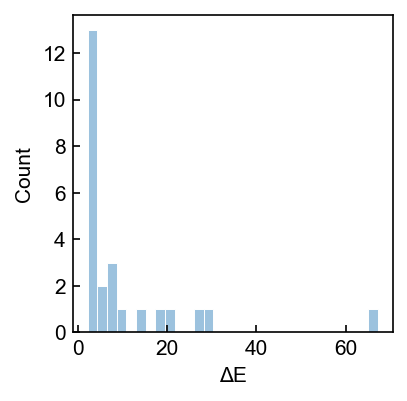

In [ ]:
plt.figure(figsize=(2.75, 2.75))

sns.histplot(cv_de, bins=30, edgecolor='white', color=sensor_colors[1])
# plt.title("LOOCV ΔE (Lab) Distribution")

plt.xlabel("ΔE")
plt.ylabel("Count")
plt.tick_params(direction='in')

plt.gca().set_position(pos_ax)
# plt.savefig('../figures/fig2/ecoflex_cam_model_deltaE_hist.png', bbox_inches='tight', dpi=600, transparent=True)
plt.show()

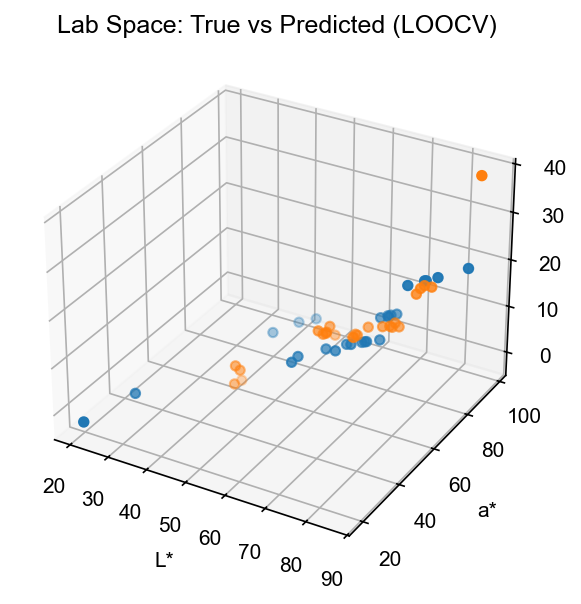

In [38]:
from mpl_toolkits.mplot3d import Axes3D  # noqa
true_lab = camrgb_to_lab(cv_trues); pred_lab = camrgb_to_lab(cv_preds)
fig = plt.figure(figsize=(4, 4))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(true_lab[:,0], true_lab[:,1], true_lab[:,2])
ax.scatter(pred_lab[:,0], pred_lab[:,1], pred_lab[:,2])
ax.set_xlabel("L*")
ax.set_ylabel("a*")
ax.set_zlabel("b*")
ax.set_title("Lab Space: True vs Predicted (LOOCV)")

plt.tight_layout()
plt.show()

In [39]:
import colour

def rgb_to_xyz(rgb):
    M = np.array([
        [0.4124564, 0.3575761, 0.1804375],
        [0.2126729, 0.7151522, 0.0721750],
        [0.0193339, 0.1191920, 0.9503041]
    ])
    return rgb @ M.T

def xyz_to_xy(XYZ):
    X, Y, Z = XYZ[...,0], XYZ[...,1], XYZ[...,2]
    denom = (X + Y + Z) + 1e-12
    x = X / denom
    y = Y / denom
    return np.stack([x, y], axis=-1)

true_xy  = xyz_to_xy(rgb_to_xyz(cv_trues))
pred_xy  = xyz_to_xy(rgb_to_xyz(cv_preds))



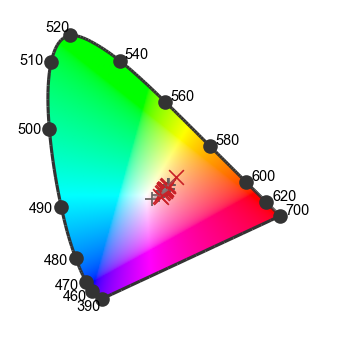

In [43]:
fig, ax = colour.plotting.plot_chromaticity_diagram_CIE1931(
    show=False,
    title=""
)

fig.set_size_inches(2.75, 2.75)
for i in range(len(true_xy)):
    ax.plot([true_xy[i,0], pred_xy[i,0]],
              [true_xy[i,1], pred_xy[i,1]],
              color='gray', ls='--', alpha=0.4, linewidth=1)
ax.scatter(true_xy[:,0], true_xy[:,1],
             facecolors='#655e5c', lw=0.8, marker='+',
             label='True', s=50)
ax.scatter(pred_xy[:,0], pred_xy[:,1],
             facecolors='#c92127', lw=0.8, marker='x',
             label='Predicted', s=50)

plt.xlim(-0.1, 0.9)
plt.ylim(-0.1, 0.9)
plt.axis('off')

ax.set_position(pos_ax)
# plt.savefig('../figures/fig2/ecoflex_matrix_on_CIE1931.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

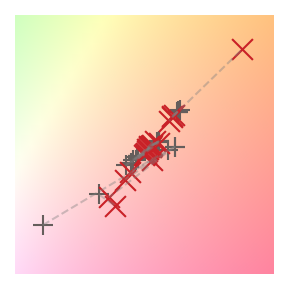

In [47]:
fig, ax = colour.plotting.plot_chromaticity_diagram_CIE1931(
    show=False,
    title=""
)

fig.set_size_inches(2, 2)
for i in range(len(true_xy)):
    ax.plot([true_xy[i,0], pred_xy[i,0]],
            [true_xy[i,1], pred_xy[i,1]],
            color='gray', ls='--', alpha=0.4, linewidth=1)
ax.scatter(true_xy[:,0], true_xy[:,1],
             facecolors='#655e5c', lw=1, marker='+',
             label='True', s=100)
ax.scatter(pred_xy[:,0], pred_xy[:,1],
             facecolors='#c92127', lw=1, marker='x',
             label='Predicted', s=100)

plt.xlim(0.32, 0.42)
plt.ylim(0.3, 0.4)
plt.axis('off')

plt.savefig('../figures/fig2/ecoflex_matrix_on_CIE1931_zoomedin.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()